In [ ]:
# Step 1: Download the dataset

import kagglehub

path = kagglehub.dataset_download("uom190346a/e-commerce-customer-behavior-dataset")
print("Path to dataset files:", path)

100%|██████████| 2.84k/2.84k [00:00<00:00, 1.50MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/uom190346a/e-commerce-customer-behavior-dataset/versions/1


In [ ]:
# Step 2: Import libraries and load the dataset

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

print("Files available:", os.listdir(path))

csv_files = [file for file in os.listdir(path) if file.lower().endswith(".csv")]
if not csv_files:
    raise FileNotFoundError("No CSV file was found in the downloaded dataset folder.")

# Use the expected filename when available; otherwise use the first CSV file.
expected_file = "E-commerce Customer Behavior - Sheet1.csv"
csv_path = os.path.join(path, expected_file) if expected_file in csv_files else os.path.join(path, csv_files[0])

df = pd.read_csv(csv_path)
print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Files available: ['E-commerce Customer Behavior - Sheet1.csv']
Dataset loaded successfully.
Shape: (350, 11)


,Customer ID,Gender,Age,City,Membership Type,Total Spend,Items Purchased,Average Rating,Discount Applied,Days Since Last Purchase,Satisfaction Level
0,101,Female,29,New York,Gold,1120.20,14,4.6,True,25,Satisfied
1,102,Male,34,Los Angeles,Silver,780.50,11,4.1,False,18,Neutral
2,103,Female,43,Chicago,Bronze,510.75,9,3.4,True,42,Unsatisfied
3,104,Male,30,San Francisco,Gold,1480.30,19,4.7,False,12,Satisfied
4,105,Male,27,Miami,Silver,720.40,13,4.0,True,55,Unsatisfied


## Step 3: Understand the dataset

Check the number of rows and columns, data types, summary statistics, and missing/duplicate values before plotting or training models.

In [ ]:
# Step 3.1: Dataset structure

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\\nColumn names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nFirst five rows:")
display(df.head())

print("\\nNumerical summary:")
display(df.describe(include=[np.number]).T)

print("\\nSummary of all columns:")
display(df.describe(include="all").T)

Rows: 350
Columns: 11
\nColumn names:
['Customer ID', 'Gender', 'Age', 'City', 'Membership Type', 'Total Spend', 'Items Purchased', 'Average Rating', 'Discount Applied', 'Days Since Last Purchase', 'Satisfaction Level']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               350 non-null    int64  
 1   Gender                    350 non-null    object 
 2   Age                       350 non-null    int64  
 3   City                      350 non-null    object 
 4   Membership Type           350 non-null    object 
 5   Total Spend               350 non-null    float64
 6   Items Purchased           350 non-null    int64  
 7   Average Rating            350 non-null    float64
 8   Discount Applied          350 non-null    bool   
 9   Days Since Last Purchase  350 n

,Customer ID,Gender,Age,City,Membership Type,Total Spend,Items Purchased,Average Rating,Discount Applied,Days Since Last Purchase,Satisfaction Level
0,101,Female,29,New York,Gold,1120.20,14,4.6,True,25,Satisfied
1,102,Male,34,Los Angeles,Silver,780.50,11,4.1,False,18,Neutral
2,103,Female,43,Chicago,Bronze,510.75,9,3.4,True,42,Unsatisfied
3,104,Male,30,San Francisco,Gold,1480.30,19,4.7,False,12,Satisfied
4,105,Male,27,Miami,Silver,720.40,13,4.0,True,55,Unsatisfied


\nNumerical summary:


,count,mean,std,min,25%,50%,75%,max
Customer ID,350.0,275.500000,101.180532,101.0,188.25,275.5,362.75,450.0
Age,350.0,33.597143,4.870882,26.0,30.00,32.5,37.00,43.0
Total Spend,350.0,845.381714,362.058695,410.8,502.00,775.2,1160.60,1520.1
Items Purchased,350.0,12.600000,4.155984,7.0,9.00,12.0,15.00,21.0
Average Rating,350.0,4.019143,0.580539,3.0,3.50,4.1,4.50,4.9
Days Since Last Purchase,350.0,26.588571,13.440813,9.0,15.00,23.0,38.00,63.0


\nSummary of all columns:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer ID,350.0,NaN,NaN,NaN,275.5,101.180532,101.0,188.25,275.5,362.75,450.0
Gender,350,2,Female,175,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,350.0,NaN,NaN,NaN,33.597143,4.870882,26.0,30.0,32.5,37.0,43.0
City,350,6,New York,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Membership Type,350,3,Gold,117,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Spend,350.0,NaN,NaN,NaN,845.381714,362.058695,410.8,502.0,775.2,1160.6,1520.1
Items Purchased,350.0,NaN,NaN,NaN,12.6,4.155984,7.0,9.0,12.0,15.0,21.0
Average Rating,350.0,NaN,NaN,NaN,4.019143,0.580539,3.0,3.5,4.1,4.5,4.9
Discount Applied,350,2,True,175,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Days Since Last Purchase,350.0,NaN,NaN,NaN,26.588571,13.440813,9.0,15.0,23.0,38.0,63.0


In [ ]:
# Step 3.2: Data-quality checks

missing_values = df.isnull().sum().sort_values(ascending=False)
print("Missing values by column:")
display(missing_values.to_frame("missing_count"))

print("Duplicate rows:", df.duplicated().sum())

print("Unique values in each column:")
display(df.nunique().sort_values().to_frame("unique_values"))

Missing values by column:


,missing_count
Satisfaction Level,2
Gender,0
Customer ID,0
Age,0
City,0
Total Spend,0
Membership Type,0
Items Purchased,0
Average Rating,0
Discount Applied,0


Duplicate rows: 0
Unique values in each column:


,unique_values
Gender,2
Discount Applied,2
Satisfaction Level,3
Membership Type,3
City,6
Items Purchased,15
Age,16
Average Rating,20
Days Since Last Purchase,54
Total Spend,76


## Step 4: Clean and prepare the data for EDA

Column names are stripped of extra spaces. Exact duplicate rows are removed. Missing values are inspected and handled later in the model pipeline so that preprocessing is learned only from the training split.

In [ ]:
# Step 4.1: Basic cleanup

df.columns = df.columns.astype(str).str.strip()
df = df.drop_duplicates().copy()

print("Shape after removing exact duplicate rows:", df.shape)
print("Column names:")
print(df.columns.tolist())

Shape after removing exact duplicate rows: (350, 11)
Column names:
['Customer ID', 'Gender', 'Age', 'City', 'Membership Type', 'Total Spend', 'Items Purchased', 'Average Rating', 'Discount Applied', 'Days Since Last Purchase', 'Satisfaction Level']


## Step 5: Exploratory Data Analysis (EDA)

The following plots explore numerical distributions, categorical distributions, correlations, and the satisfaction target. EDA helps identify patterns and data issues before modelling.

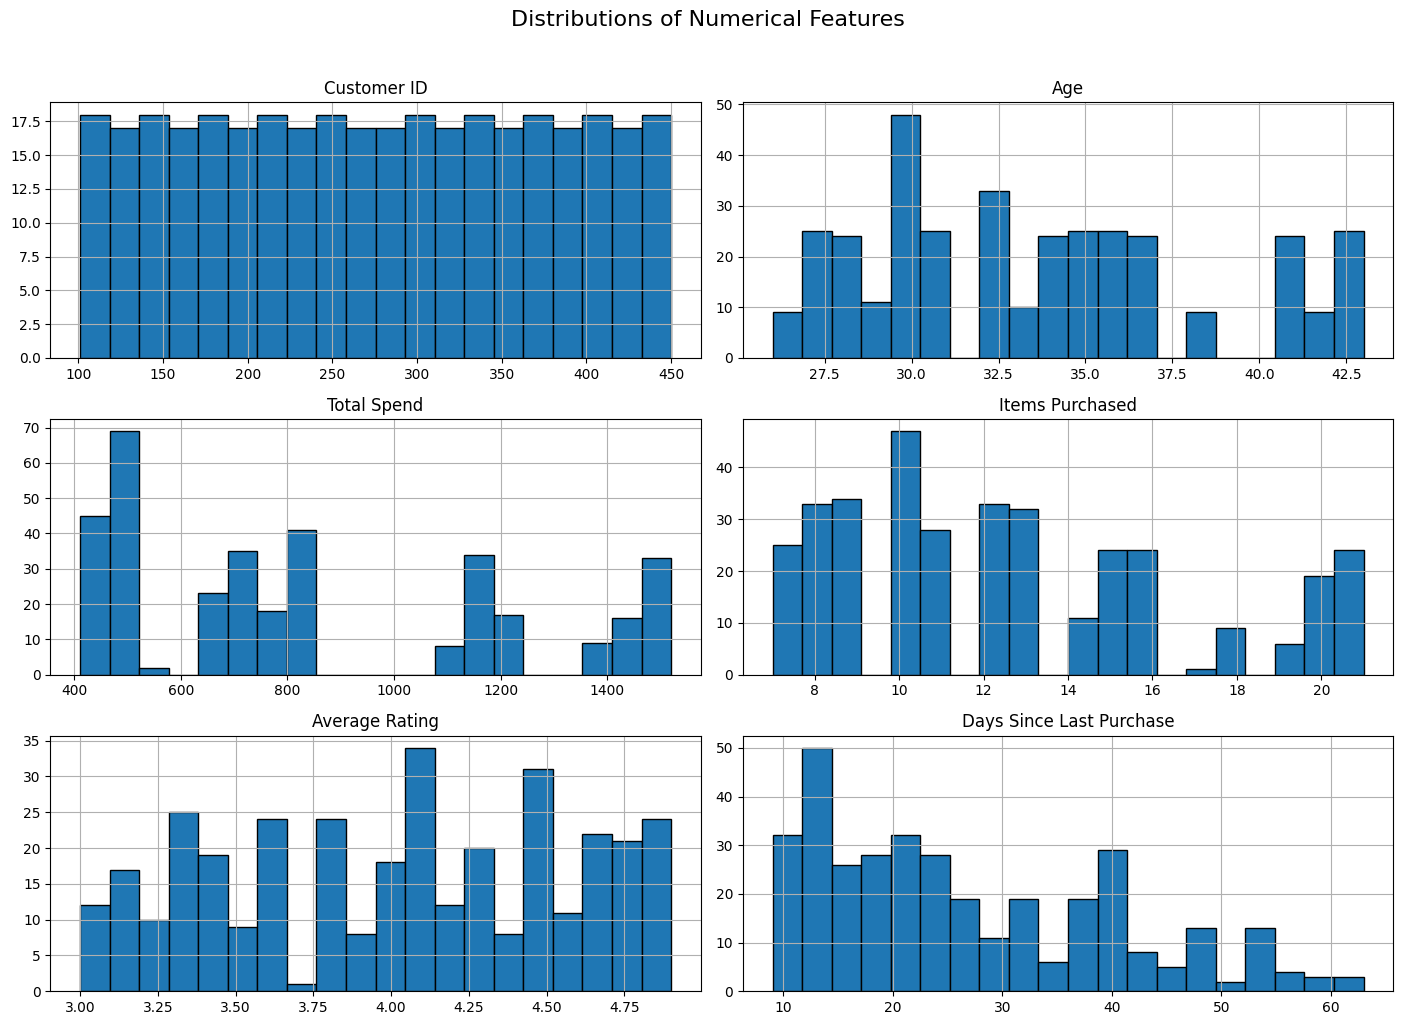

In [ ]:
# Step 5.1: Numerical feature distributions

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

if numeric_cols:
    df[numeric_cols].hist(figsize=(14, 10), bins=20, edgecolor="black")
    plt.suptitle("Distributions of Numerical Features", y=1.02, fontsize=16)
    plt.tight_layout()
    plt.show()
else:
    print("No numerical columns were detected.")

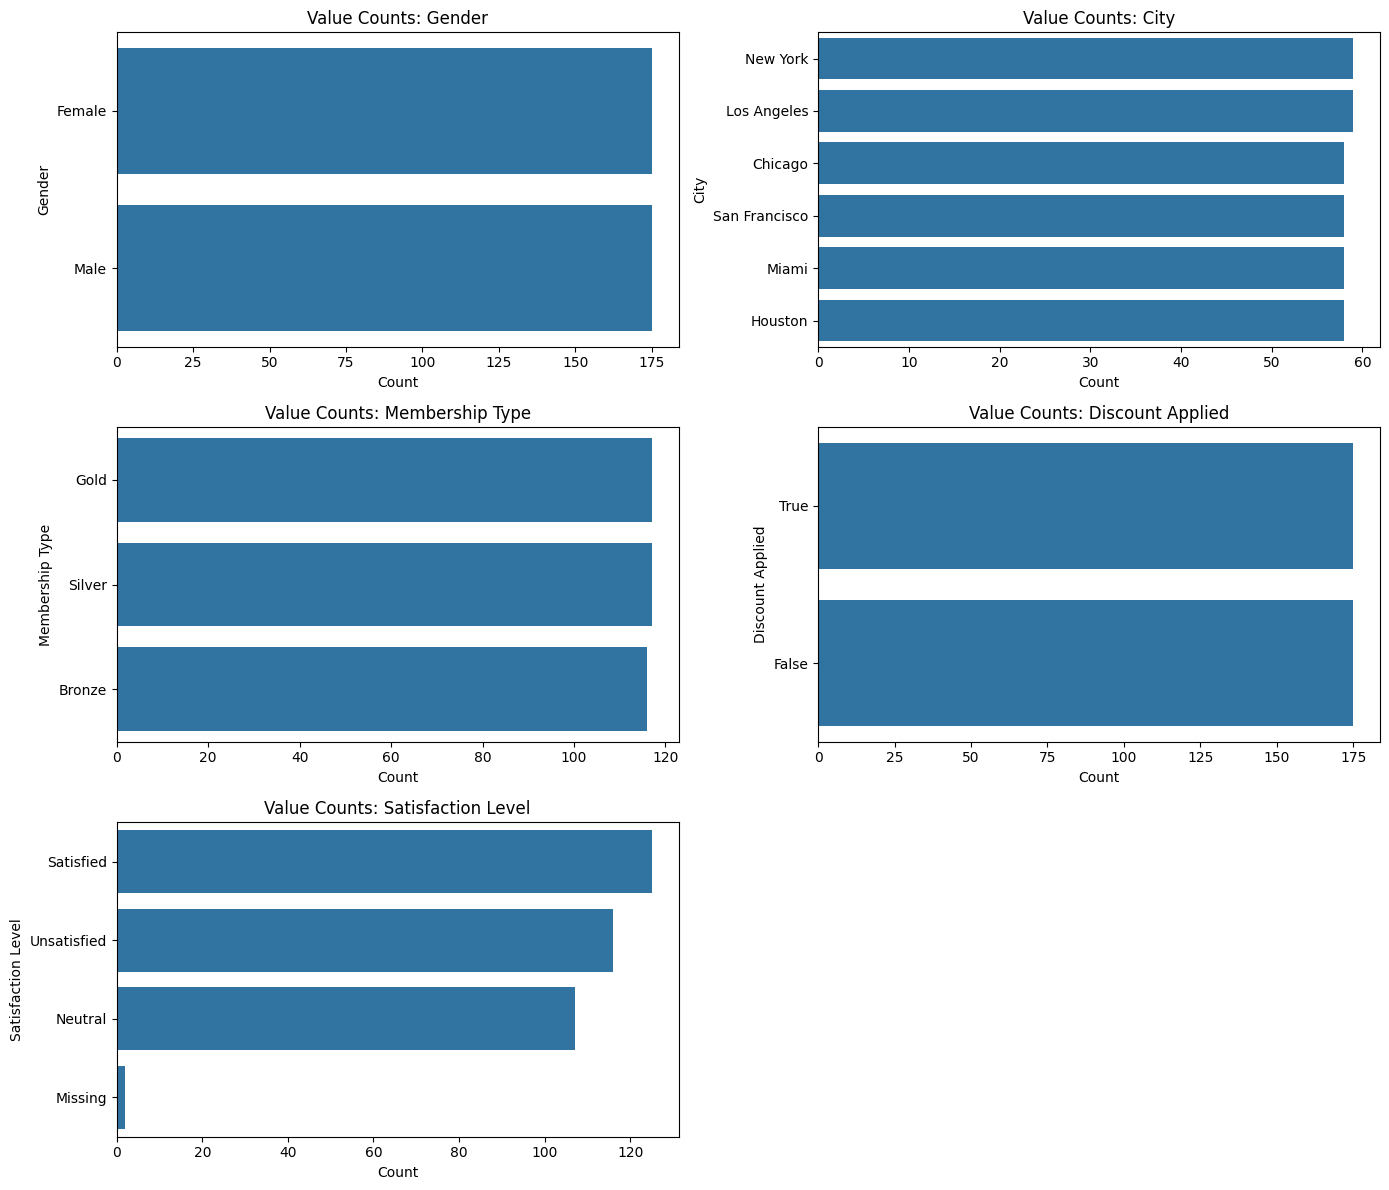

In [ ]:
# Step 5.2: Categorical feature distributions

categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

if categorical_cols:
    n_cols = 2
    n_rows = int(np.ceil(len(categorical_cols) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
    axes = np.array(axes).reshape(-1)

    for ax, col in zip(axes, categorical_cols):
        counts = df[col].astype("string").fillna("Missing").value_counts().head(15)
        sns.barplot(x=counts.values, y=counts.index, ax=ax)
        ax.set_title(f"Value Counts: {col}")
        ax.set_xlabel("Count")
        ax.set_ylabel(col)

    for ax in axes[len(categorical_cols):]:
        ax.remove()

    plt.tight_layout()
    plt.show()
else:
    print("No categorical columns were detected.")

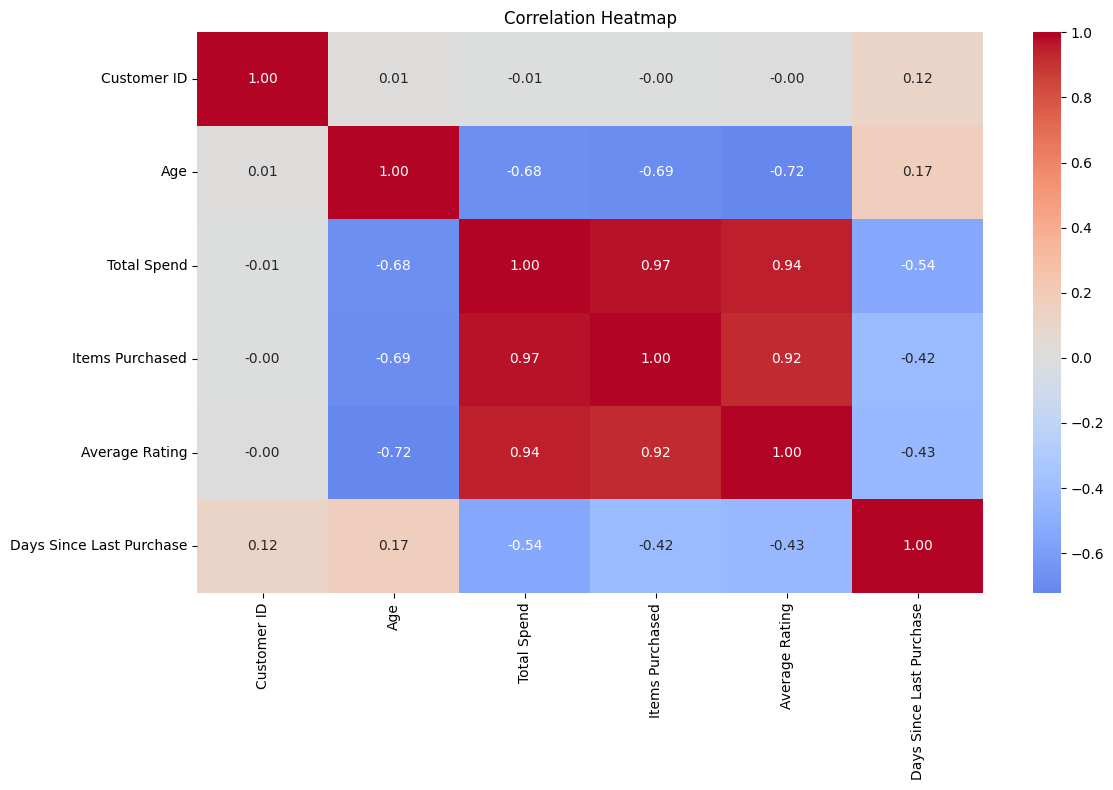

In [ ]:
# Step 5.3: Correlation heatmap for numerical features

if len(numeric_cols) >= 2:
    plt.figure(figsize=(12, 8))
    correlation = df[numeric_cols].corr(numeric_only=True)
    sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numerical columns are needed for a correlation heatmap.")

## Step 6: Select the target and inspect class balance

The target is the customer satisfaction label. The code looks for common column-name variants and stops with a clear message if it cannot identify a target. Review the selected target before proceeding.

In [ ]:
# Step 6.1: Identify the satisfaction target column

target_candidates = [
    "Satisfaction Level", "Satisfaction", "Customer Satisfaction",
    "Satisfaction_Level", "satisfaction_level", "satisfaction"
]

normalised_columns = {str(col).strip().lower().replace("_", " ").replace("-", " "): col for col in df.columns}
target_col = None

for candidate in target_candidates:
    key = candidate.lower().replace("_", " ").replace("-", " ")
    if key in normalised_columns:
        target_col = normalised_columns[key]
        break

# Fallback: look for a column containing both 'satisfaction' and not 'score' if possible.
if target_col is None:
    possible = [col for col in df.columns if "satisfaction" in str(col).lower()]
    if possible:
        target_col = possible[0]

if target_col is None:
    raise ValueError(
        "Could not identify the satisfaction target column. "
        "Please check df.columns and set target_col to the exact target-column name."
    )

print("Selected target column:", target_col)
print("\\nTarget values (including missing):")
print(df[target_col].value_counts(dropna=False))

Selected target column: Satisfaction Level
\nTarget values (including missing):
Satisfaction Level
Satisfied      125
Unsatisfied    116
Neutral        107
NaN              2
Name: count, dtype: int64


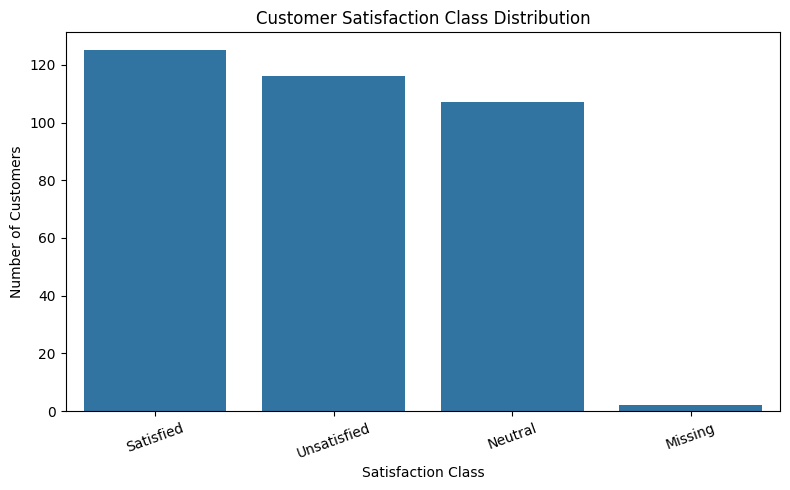

Class proportions:


,percentage
Satisfaction Level,
Satisfied,35.71
Unsatisfied,33.14
Neutral,30.57
NaN,0.57


In [ ]:
# Step 6.2: Visualise satisfaction class balance

target_counts = df[target_col].astype("string").fillna("Missing").value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=target_counts.index, y=target_counts.values)
plt.title("Customer Satisfaction Class Distribution")
plt.xlabel("Satisfaction Class")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print("Class proportions:")
display((df[target_col].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame("percentage"))

## Step 7: Prepare features and split the data

Rows without a target label are excluded because they cannot be used for supervised learning. The target column is removed from the input features to avoid leakage. The train/test split is stratified when possible so each class is represented proportionally in both sets.

In [ ]:
# Step 7.1: Separate features (X) and target (y)

model_df = df.dropna(subset=[target_col]).copy()
X = model_df.drop(columns=[target_col])
y = model_df[target_col].astype(str).str.strip()

# Remove columns that are entirely missing.
X = X.dropna(axis=1, how="all")

# Remove likely identifier columns: IDs usually identify a row rather than explain satisfaction.
id_like_cols = [
    col for col in X.columns
    if str(col).strip().lower().replace("_", " ").replace("-", " ") in
    {"customer id", "customerid", "id", "user id", "userid", "row id"}
]
if id_like_cols:
    print("Dropping identifier column(s):", id_like_cols)
    X = X.drop(columns=id_like_cols)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", sorted(y.unique().tolist()))
display(X.head())

Dropping identifier column(s): ['Customer ID']
Feature matrix shape: (348, 9)
Target shape: (348,)
Target classes: ['Neutral', 'Satisfied', 'Unsatisfied']


,Gender,Age,City,Membership Type,Total Spend,Items Purchased,Average Rating,Discount Applied,Days Since Last Purchase
0,Female,29,New York,Gold,1120.20,14,4.6,True,25
1,Male,34,Los Angeles,Silver,780.50,11,4.1,False,18
2,Female,43,Chicago,Bronze,510.75,9,3.4,True,42
3,Male,30,San Francisco,Gold,1480.30,19,4.7,False,12
4,Male,27,Miami,Silver,720.40,13,4.0,True,55


In [ ]:
# Step 7.2: Train/test split

from sklearn.model_selection import train_test_split

class_counts = y.value_counts()
stratify_target = y if len(class_counts) > 1 and class_counts.min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=stratify_target
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("\\nTraining target distribution:")
display(y_train.value_counts(normalize=True).round(3).to_frame("proportion"))
print("Testing target distribution:")
display(y_test.value_counts(normalize=True).round(3).to_frame("proportion"))

Training rows: 278
Testing rows: 70
\nTraining target distribution:


,proportion
Satisfaction Level,
Satisfied,0.360
Unsatisfied,0.335
Neutral,0.306


Testing target distribution:


,proportion
Satisfaction Level,
Satisfied,0.357
Unsatisfied,0.329
Neutral,0.314


## Step 8: Build preprocessing and classification pipelines

Numerical columns are imputed with the median and scaled for Logistic Regression. Categorical columns are imputed with the most frequent value and one-hot encoded. All preprocessing is fitted on the training data only, reducing data leakage.

In [ ]:
# Step 8.1: Create preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [col for col in X_train.columns if col not in numeric_features]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['Age', 'Total Spend', 'Items Purchased', 'Average Rating', 'Days Since Last Purchase']
Categorical features: ['Gender', 'City', 'Membership Type', 'Discount Applied']


In [ ]:
# Step 8.2: Define classification models

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )
}

print("Models prepared:", list(models.keys()))

Models prepared: ['Logistic Regression', 'Decision Tree', 'Random Forest']


## Step 9: Train and compare models

Each model uses the same train/test split and preprocessing. Accuracy alone can hide poor performance on a minority class, so we also compare weighted precision, recall, and F1-score. The weighted F1-score is used to select the best model from this initial comparison.

In [ ]:
# Step 9.1: Train models and evaluate test-set performance

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

trained_models = {}
results = []

for name, classifier in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    trained_models[name] = pipeline
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-score (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1-score (weighted)", ascending=False).reset_index(drop=True)
display(results_df.round(4))

,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
0,Decision Tree,1.0000,1.0000,1.0000,1.0000
1,Random Forest,1.0000,1.0000,1.0000,1.0000
2,Logistic Regression,0.9714,0.9738,0.9714,0.9715


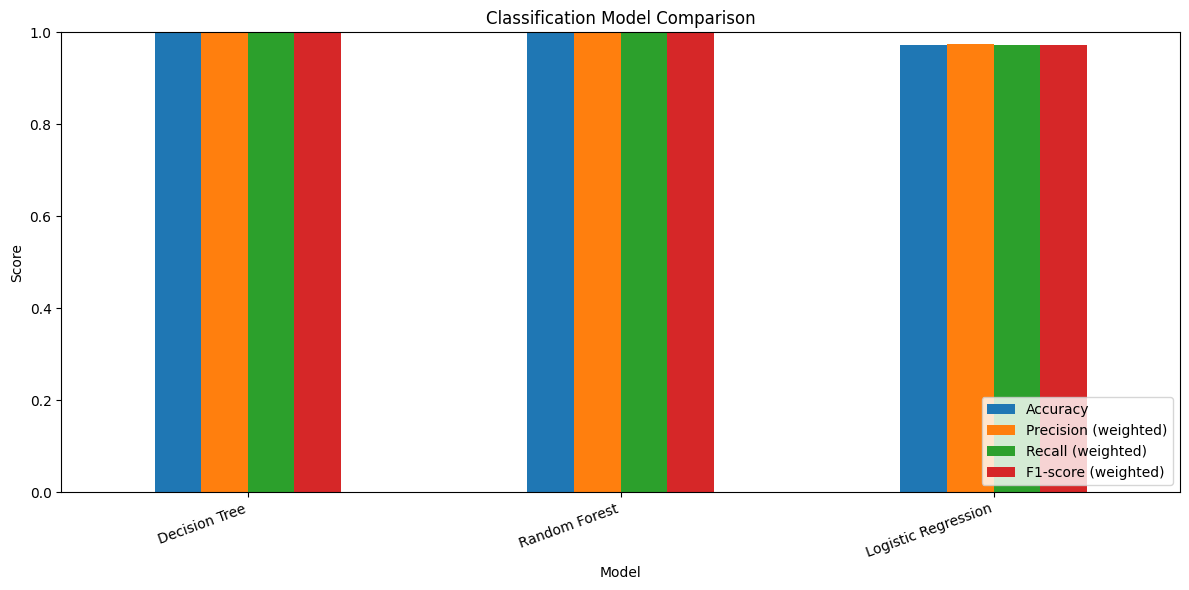

In [ ]:
# Step 9.2: Compare model scores visually

plot_df = results_df.set_index("Model")[["Accuracy", "Precision (weighted)", "Recall (weighted)", "F1-score (weighted)"]]
plot_df.plot(kind="bar", figsize=(12, 6), ylim=(0, 1))
plt.title("Classification Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Step 10: Evaluate the best model in detail

The best model is selected using weighted F1-score on the held-out test set. The classification report shows per-class precision, recall, and F1-score. The confusion matrix shows which satisfaction classes are confused with one another.

In [ ]:
# Step 10.1: Best model and classification report

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Best model based on weighted F1-score:", best_model_name)
print("\\nClassification report:")
print(classification_report(y_test, best_predictions, zero_division=0))

Best model based on weighted F1-score: Decision Tree
\nClassification report:
              precision    recall  f1-score   support

     Neutral       1.00      1.00      1.00        22
   Satisfied       1.00      1.00      1.00        25
 Unsatisfied       1.00      1.00      1.00        23

    accuracy                           1.00        70
   macro avg       1.00      1.00      1.00        70
weighted avg       1.00      1.00      1.00        70



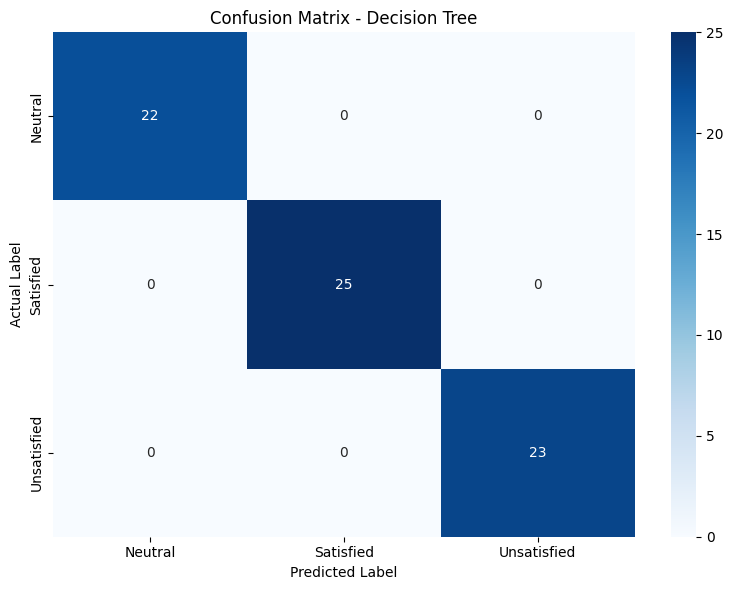

In [ ]:
# Step 10.2: Confusion matrix

labels = sorted(y.unique().tolist())
cm = confusion_matrix(y_test, best_predictions, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=labels, yticklabels=labels
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

## Step 11: Understand which features matter

For tree-based models, feature importance is available directly. For other models, permutation importance estimates how much test-set performance changes when a feature is shuffled. This is a useful interpretation aid, not proof that a feature causes satisfaction.

,Feature,Importance,Std
7,Discount Applied,0.3132,0.0429
4,Total Spend,0.2583,0.0590
5,Items Purchased,0.1981,0.0326
6,Average Rating,0.0764,0.0348
0,Gender,0.0000,0.0000
3,Membership Type,0.0000,0.0000
2,City,0.0000,0.0000
1,Age,0.0000,0.0000
8,Days Since Last Purchase,0.0000,0.0000


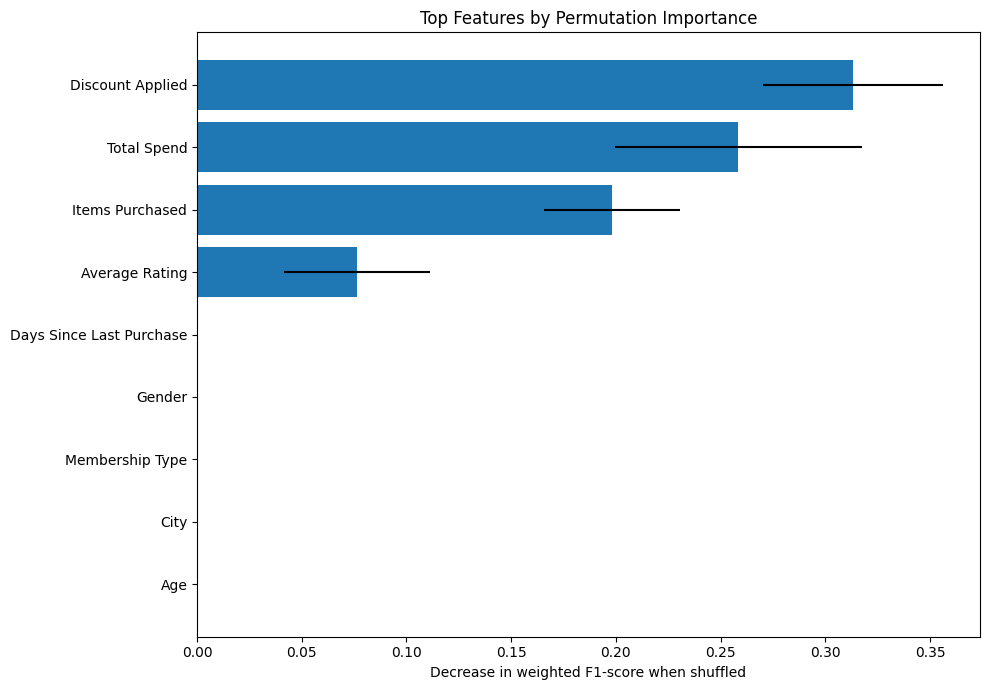

In [ ]:
# Step 11.1: Calculate permutation feature importance

from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="f1_weighted",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": permutation_result.importances_mean,
    "Std": permutation_result.importances_std
}).sort_values("Importance", ascending=False)

display(importance_df.head(15).round(4))

top_features = importance_df.head(15).sort_values("Importance")
plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"].astype(str), top_features["Importance"], xerr=top_features["Std"])
plt.title("Top Features by Permutation Importance")
plt.xlabel("Decrease in weighted F1-score when shuffled")
plt.tight_layout()
plt.show()

## Step 12: Make a prediction for a customer

Use a row from the test set to demonstrate prediction with the same feature columns used during training. You can also create a new one-row DataFrame, but its column names and data types should match the training features.

In [ ]:
# Step 12.1: Predict satisfaction for one example customer

sample_customer = X_test.iloc[[0]]
actual_label = y_test.iloc[0]
predicted_label = best_model.predict(sample_customer)[0]

print("Customer input:")
display(sample_customer)
print("Actual satisfaction:", actual_label)
print("Predicted satisfaction:", predicted_label)

if hasattr(best_model, "predict_proba"):
    probabilities = best_model.predict_proba(sample_customer)[0]
    probability_df = pd.DataFrame({
        "Satisfaction class": best_model.named_steps["classifier"].classes_,
        "Predicted probability": probabilities
    }).sort_values("Predicted probability", ascending=False)
    display(probability_df.round(4))

Customer input:


,Gender,Age,City,Membership Type,Total Spend,Items Purchased,Average Rating,Discount Applied,Days Since Last Purchase
32,Female,42,Chicago,Bronze,520.4,9,3.5,True,37


Actual satisfaction: Unsatisfied
Predicted satisfaction: Unsatisfied


,Satisfaction class,Predicted probability
2,Unsatisfied,1.0
0,Neutral,0.0
1,Satisfied,0.0


In [ ]:
#Predict Satisfaction for a New Customer

import pandas as pd
import numpy as np

print("=" * 60)
print("    E-COMMERCE CUSTOMER SATISFACTION PREDICTION")
print("=" * 60)

# Collect input from the user
customer_data = {}

for column in X.columns:
    print(f"\nEnter value for {column}")

    if pd.api.types.is_numeric_dtype(X[column]):
        while True:
            try:
                value = float(input(f"{column}: "))

                # Convert whole numbers back to integers
                if value.is_integer():
                    value = int(value)

                customer_data[column] = value
                break

            except ValueError:
                print("Invalid input! Please enter a numeric value.")

    else:

        categories = X[column].dropna().unique().tolist()

        print("Available values:", categories)

        value = input(f"{column}: ").strip()

        customer_data[column] = value

new_customer = pd.DataFrame([customer_data], columns=X.columns)

print("\nCustomer Details:")
display(new_customer)

# Predicting satisfaction
predicted_satisfaction = best_model.predict(new_customer)[0]

print("\n" + "=" * 60)
print("PREDICTED CUSTOMER SATISFACTION:", predicted_satisfaction)
print("=" * 60)

# Display prediction probabilities
if hasattr(best_model, "predict_proba"):
    probabilities = best_model.predict_proba(new_customer)[0]

    probability_df = pd.DataFrame({
        "Satisfaction Class":
            best_model.named_steps["classifier"].classes_,
        "Probability (%)": probabilities * 100
    }).sort_values("Probability (%)", ascending=False)

    print("\nPrediction Probabilities:")
    display(probability_df.round(2).reset_index(drop=True))

    E-COMMERCE CUSTOMER SATISFACTION PREDICTION

Enter value for Gender
Available values: ['Female', 'Male']
Gender: Male

Enter value for Age
Age: 34

Enter value for City
Available values: ['New York', 'Los Angeles', 'Chicago', 'San Francisco', 'Miami', 'Houston']
City: New Tork

Enter value for Membership Type
Available values: ['Gold', 'Silver', 'Bronze']
Membership Type: gold

Enter value for Total Spend
Total Spend: 420

Enter value for Items Purchased
Items Purchased: 13

Enter value for Average Rating
Average Rating: 3.6

Enter value for Discount Applied
Discount Applied: 23

Enter value for Days Since Last Purchase
Days Since Last Purchase: 32

Customer Details:


,Gender,Age,City,Membership Type,Total Spend,Items Purchased,Average Rating,Discount Applied,Days Since Last Purchase
0,Male,34,New Tork,gold,420,13,3.6,23,32



PREDICTED CUSTOMER SATISFACTION: Unsatisfied

Prediction Probabilities:


,Satisfaction Class,Probability (%)
0,Unsatisfied,100.0
1,Neutral,0.0
2,Satisfied,0.0


In [ ]:

# Step 13.1: Final Project Summary

print("=" * 60)
print("       E-COMMERCE CUSTOMER SATISFACTION PREDICTION")
print("=" * 60)

# 1. Dataset information
print("\n1. DATASET INFORMATION")
print("-" * 40)

print("Total rows used for modeling:", len(X))
print("Total features used:", X.shape[1])
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# 2. Target classes and distribution
print("\n2. TARGET CLASSES AND DISTRIBUTION")
print("-" * 40)

print("Target column:", target_col)
print("Target classes:", y.unique().tolist())

class_distribution = y.value_counts()

for label, count in class_distribution.items():
    percentage = (count / len(y)) * 100
    print(f"{label}: {count} customers ({percentage:.2f}%)")

# 3. Best-performing model
print("\n3. BEST-PERFORMING MODEL")
print("-" * 40)

print("Best model:", best_model_name)

# 4. Test performance
print("\n4. MODEL PERFORMANCE")
print("-" * 40)

best_result = results_df.iloc[0]

print(f"Test Accuracy: {best_result['Accuracy']:.4f}")
print(f"Weighted Precision: {best_result['Precision (weighted)']:.4f}")
print(f"Weighted Recall: {best_result['Recall (weighted)']:.4f}")
print(f"Weighted F1-score: {best_result['F1-score (weighted)']:.4f}")

# 5. Most influential features
print("\n5. TOP 5 INFLUENTIAL FEATURES")
print("-" * 40)

top_5_features = importance_df.head(5)

for index, row in enumerate(
    top_5_features.itertuples(index=False),
    start=1
):
    print(f"{index}. {row.Feature}: {row.Importance:.4f}")

# 6. Limitations and improvements
print("\n6. LIMITATIONS AND FUTURE IMPROVEMENTS")
print("-" * 40)

limitations = [
    "Model performance depends on dataset quality and size.",
    "Imbalanced target classes can affect minority-class predictions.",
    "Target leakage may produce misleadingly high evaluation scores.",
    "The model has not necessarily been tuned for optimal performance."
]

for index, limitation in enumerate(limitations, start=1):
    print(f"{index}. {limitation}")

improvements = [
    "Use cross-validation and hyperparameter tuning.",
    "Evaluate precision, recall, and F1-score for every class.",
    "Investigate class imbalance and apply suitable techniques if needed.",
    "Remove features that reveal the target label directly."
]

print("\nRecommended improvements:")

for index, improvement in enumerate(improvements, start=1):
    print(f"{index}. {improvement}")

print("\n" + "=" * 60)
print("             PROJECT SUMMARY COMPLETED")
print("=" * 60)


       E-COMMERCE CUSTOMER SATISFACTION PREDICTION

1. DATASET INFORMATION
----------------------------------------
Total rows used for modeling: 348
Total features used: 9
Training samples: 278
Testing samples: 70

2. TARGET CLASSES AND DISTRIBUTION
----------------------------------------
Target column: Satisfaction Level
Target classes: ['Satisfied', 'Neutral', 'Unsatisfied']
Satisfied: 125 customers (35.92%)
Unsatisfied: 116 customers (33.33%)
Neutral: 107 customers (30.75%)

3. BEST-PERFORMING MODEL
----------------------------------------
Best model: Decision Tree

4. MODEL PERFORMANCE
----------------------------------------
Test Accuracy: 1.0000
Weighted Precision: 1.0000
Weighted Recall: 1.0000
Weighted F1-score: 1.0000

5. TOP 5 INFLUENTIAL FEATURES
----------------------------------------
1. Discount Applied: 0.3132
2. Total Spend: 0.2583
3. Items Purchased: 0.1981
4. Average Rating: 0.0764
5. Gender: 0.0000

6. LIMITATIONS AND FUTURE IMPROVEMENTS
---------------------------